# Step 1: Notebook Setup

Importing dataset, categroies, and setting up project variables.

* `SEED` is fixed so that every run gives the same clusters.
* The sector and the fuel are read from the SEDS column names (3rd/4th and 1st/2nd characters, from the SEDS documentation guide). This is simpler and safer than parsing the description text.
* Population (`TPOPP`) is only used to compute per-capita values; it is not a clustering feature.


In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Global Settings Values
SEED = 42                                # Multiple runs to give same clusters
INPUT_DIR = ""
OUTPUT_DIR = os.getcwd() + "/../Datasets/SEDS"
SEDS_CLEANED_CSV = "df_seds_cleaned.csv"
SEDS_CATEGORIES_XLSX = "SEDS_categories.xlsx"
SEDS_CLUSTERS_CSV = "df_seds_state_clusters.csv"

# Dataset Specific
ID_COLS = ["State", "Year"]              # Define data pair columns
POP_COL = "TPOPP"                        # Value of Population; Used for Per-Capita Analysis
SECTOR_CODES = {"AC": "Transportation",  # Sector codes: the 3rd/4th characters SEDS columns
                "CC": "Commercial",
                "EG": "Electric_Power",
                "EI": "Electric_Power",
                "IC": "Industrial",
                "RC": "Residential",
                "PR": "Production",
                "MP": "Production",
                "FD": "Production"}
ENERGY_CODES = {"BD": "Biodiesel",       # Energy codes: the 1st/2nd characters of SEDS columns
                "B1": "Renewable diesel",
                "CL": "Coal",
                "EM": "Fuel ethanol",
                "GE": "Geothermal",
                "HY": "Hydropower",
                "NG": "Natural gas",
                "NU": "Nuclear",
                "PA": "Petroleum",
                "SO": "Solar",
                "WW": "Wood and waste",
                "WY": "Wind",
                "RE": "Non-combustible renewables"}  # RE = the renewables combined in Step 2.2

In [2]:
# Check if in Google Colab Environment for file loading
if 'google.colab' in sys.modules:
    print("Running in Google Colab")
    from google.colab import drive
    drive.mount('/content/gdrive')
    INPUT_DIR = '/content/gdrive/MyDrive/SIADS_696_Milestone_II/Datasets/EIA_files'
else:
    print("Running in a local environment")
    INPUT_DIR = os.getcwd() + "/../Datasets/SEDS"
print(f"Input Directory: {INPUT_DIR}")
print(f"Output Driectory: {OUTPUT_DIR}")

Running in a local environment
Input Directory: /home/micleone/SIADS_696_F26_Team10/Notebooks/../Datasets/SEDS
Output Driectory: /home/micleone/SIADS_696_F26_Team10/Notebooks/../Datasets/SEDS


In [3]:
# Load cleaned dataset
df = pd.read_csv(os.path.join(INPUT_DIR, SEDS_CLEANED_CSV))
df_raw = df.copy()   # untouched copy, used later by the sensitivity analysis
energy_cols = [c for c in df.columns if c not in ID_COLS + [POP_COL]]
print("Rows x columns :", df.shape)
print("States         :", df["State"].nunique())
print("Years          :", df["Year"].min(), "-", df["Year"].max())
print("Rows per state :", sorted(df.groupby("State").size().unique().tolist()))
print("Missing values :", int(df.isna().sum().sum()))
print("Energy columns :", len(energy_cols))
df.sample(5)

Rows x columns : (3315, 56)
States         : 51
Years          : 1960 - 2024
Rows per state : [65]
Missing values : 0
Energy columns : 53


,State,Year,B1ACB,B1PRB,BDACB,BDCCB,BDEIB,BDFDB,BDRCB,CLACB,...,SORCB,TPOPP,WWCCB,WWEIB,WWICB,WWPRB,WYCCB,WYEGB,WYICB,WYPRB
3135,WI,1975,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,...,0.0,4579.0,223.0,0.0,32904.0,44874.0,0.0,0.0,0.0,0.0
1535,MN,2000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,287.0,4934.0,2020.0,8783.0,35663.0,54396.0,0.0,2472.0,0.0,2472.0
1671,MS,2006,0.0,0.0,489.0,0.0,0.0,150.0,0.0,0.0,...,9.0,2905.0,720.0,0.0,57473.0,62483.0,0.0,0.0,0.0,0.0
2912,UT,2012,0.0,0.0,384.0,0.0,0.0,463.0,0.0,0.0,...,71.0,2854.0,123.0,1314.0,201.0,2545.0,0.0,2402.0,0.0,2402.0
1669,MS,2004,0.0,0.0,50.0,0.0,0.0,0.0,0.0,0.0,...,9.0,2889.0,578.0,0.0,56746.0,60777.0,0.0,0.0,0.0,0.0


In [4]:
# Load hand-made categories
# Original Source: https://www.eia.gov/energyexplained/us-energy-facts/
df_categories = pd.read_excel(os.path.join(INPUT_DIR, SEDS_CATEGORIES_XLSX))
df_categories.sample(5)

,Category 0,Category 1,Category 2,Category 3,MSN Code,Description,Unit
29,Consumption,Renewable Energy,Non-Combustible,Solar,SORCB,Solar energy consumed by the residential sector,Billion Btu
1,Consumption,Fossil Fuels,Petroleum,Petroleum,PAACB,All petroleum products consumed by the transpo...,Billion Btu
26,Consumption,Renewable Energy,Non-Combustible,Solar,SOCCB,Solar energy consumed by the commercial sector,Billion Btu
0,Production,Fossil Fuels,Petroleum,Petroleum,PAPRB,Crude oil production (including lease condensate),Billion Btu
10,Consumption,Fossil Fuels,Natural Gas,Natural Gas,NGICB,Natural gas consumed by the industrial sector ...,Billion Btu


# Step 2: Feature Engineering

Exploring and finalizing features to be used.
1. More Cleaning: Duplicated and Empty Features
2. Domain Knowledge Adjustment: Combining Non-Combustible Renewables, Getting Trajectories, and Modifiying to Per-Capita
3. Pre-Processing: Transforming with Log Function and Standard Scaling

Why this order:
1. Clean first (duplicates, empty columns), so nothing useless is carried through the later steps.
2. Combine before the log, because the log of a sum is not the sum of the logs.
3. Windows and per-capita can be done in either order (in a test, doing per-capita before the windows gave the same clusters).
4. Log, then scale: the log tames the skew first, and scaling comes last so that every feature has the same weight in the distances.
5. Scale before the one-row-per-state step (Step 2.4). Scaling after it would standardize every window column separately across the states and remove the trend over time that all states share.

## Step 2.1: More Cleaning

Duplicated and Empty Features.

* Duplicates: `NUPRB` (nuclear production) is identical to `NUEGB` (nuclear used for electricity). Keeping both would count nuclear twice.
* Empty columns: after standardizing, a column that is almost always zero turns each of its few non-zero rows into an extreme outlier (10 or more standard deviations), which creates clusters out of a handful of rows. Columns that are non-zero in 1% of the rows or less are dropped. The 1% cut-off is tested in the sensitivity analysis.


In [5]:
# Drop Duplicated Features
print("Checking for duplicate columns...")
current_energy_cols = [col for col in df.columns if col not in ID_COLS + [POP_COL]]

dup_mask = df[current_energy_cols].T.duplicated(keep=False)
duplicated_all = df[current_energy_cols].columns[dup_mask]

if len(duplicated_all) > 0:
    print("Found matching identical columns:")
    groups = {}
    for col in duplicated_all:
        col_vals = tuple(df[col].values)
        groups.setdefault(col_vals, []).append(col)

    for i, match_group in enumerate(groups.values(), 1):
        print(f"  Group {i}: {match_group}")

    duplicate_cols_to_drop = []
    for match_group in groups.values():
        duplicate_cols_to_drop.extend(match_group[1:])

    df.drop(columns=duplicate_cols_to_drop, inplace=True)
    print(f"Dropped {len(duplicate_cols_to_drop)} duplicate column(s): {duplicate_cols_to_drop}")
    energy_combined_cols = [col for col in current_energy_cols if col not in duplicate_cols_to_drop]
else:
    print("No duplicate columns found.")

Checking for duplicate columns...
Found matching identical columns:
  Group 1: ['NUEGB', 'NUPRB']
Dropped 1 duplicate column(s): ['NUPRB']


In [6]:
# Drop features that are mostly zero per variable threshold
print("Checking for empty columns...")
EMPTY_THRESHOLD = 0.01
current_energy_cols = [col for col in df.columns if col not in ID_COLS + [POP_COL]]

total_rows = len(df)
empty_cols_to_drop = []

for col in current_energy_cols:
    col_non_zero = (df[col] != 0).sum()
    ratio_across_state_years = col_non_zero / total_rows
    if ratio_across_state_years < EMPTY_THRESHOLD:
        empty_cols_to_drop.append(col)
        print(f"Column '{col}' has non-zeros in only {ratio_across_state_years:.1%} of all state-years (< {EMPTY_THRESHOLD:.1%}).")

if len(empty_cols_to_drop) > 0:
    df.drop(columns=empty_cols_to_drop, inplace=True)
    print(f"\nDropped {len(empty_cols_to_drop)} column(s) under the global state-years threshold: {empty_cols_to_drop}")
    energy_cols = [col for col in energy_cols if col not in empty_cols_to_drop]
else:
    print("No columns fell below the global state-years threshold.")

Checking for empty columns...
Column 'B1ACB' has non-zeros in only 0.8% of all state-years (< 1.0%).
Column 'BDCCB' has non-zeros in only 1.0% of all state-years (< 1.0%).
Column 'BDRCB' has non-zeros in only 1.0% of all state-years (< 1.0%).

Dropped 3 column(s) under the global state-years threshold: ['B1ACB', 'BDCCB', 'BDRCB']


## Step 2.2: Domain Knowledge Adjustment

Combining Non-Combustible Renewables, Getting Windows, and Modifiying to Per-Capita.

* Combine the non-combustible renewables (hydro, wind, solar, geothermal): they are separate columns, many of them almost always zero because wind and solar only appear late. One value per sector is more stable. It also means the model cannot tell which of those fuels is behind a cluster, so cluster names should not claim one. The combustible renewables (wood and waste, biofuels) are left separate, because they are burned.
* Trajectories: one cluster per state needs one row per state. Averaging the years into 5-year windows smooths year-to-year noise but keeps 13 steps of history, and every year from 1960 to 2024 is used. Other window lengths are tested in the sensitivity analysis.
* Per capita: removes the effect of state size, so large states such as CA and TX do not dominate the distances.


In [7]:
# Combine Non-combustible renewables since they are assumed distinctly different
# from combustible renewables in regards to environmental effects
re_energy_code = "RE"
print(f"Combining Renewables using '{re_energy_code}' prefix with Category 2 and dropping original columns...")
msn_to_cat2 = dict(zip(df_categories["MSN Code"], df_categories["Category 2"]))
active_energy_cols = [col for col in df.columns if col not in ID_COLS + [POP_COL]]

aggregated_data = {}

for col in active_energy_cols:
    category2_val = msn_to_cat2.get(col)
    is_renewable = category2_val == "Non-Combustible"

    # Replace the first two characters with "RE"
    if is_renewable:

        sector_code = col[2:4]

        # Combine few different energy codes since they mean the same
        if sector_code in ["PR", "MP", "FD"]:
            sector_code = "PR"
        elif sector_code in ["EG", "EI"]:
            sector_code = "EI"

        new_col = re_energy_code + sector_code + col[4:]
        if new_col in aggregated_data:
            aggregated_data[new_col] += df[col]
        else:
            aggregated_data[new_col] = df[col].copy()
    else:
        aggregated_data[col] = df[col].copy()

# Create the new combined df
df = df[ID_COLS + [POP_COL]].copy()
for col_name, data_series in aggregated_data.items():
    df[col_name] = data_series

print("Combined DataFrame shape:", df.shape)
print("Columns:", list(df.columns))
display(df.sample(5))

Combining Renewables using 'RE' prefix with Category 2 and dropping original columns...
Combined DataFrame shape: (3315, 39)
Columns: ['State', 'Year', 'TPOPP', 'B1PRB', 'BDACB', 'BDEIB', 'BDFDB', 'CLACB', 'CLCCB', 'CLEIB', 'CLICB', 'CLPRB', 'CLRCB', 'EMACB', 'EMCCB', 'EMFDB', 'EMICB', 'RECCB', 'REEIB', 'REICB', 'REPRB', 'RERCB', 'NGACB', 'NGCCB', 'NGEIB', 'NGICB', 'NGMPB', 'NGRCB', 'NUEGB', 'PAACB', 'PACCB', 'PAEIB', 'PAICB', 'PAPRB', 'PARCB', 'WWCCB', 'WWEIB', 'WWICB', 'WWPRB']


,State,Year,TPOPP,B1PRB,BDACB,BDEIB,BDFDB,CLACB,CLCCB,CLEIB,...,PAACB,PACCB,PAEIB,PAICB,PAPRB,PARCB,WWCCB,WWEIB,WWICB,WWPRB
1725,MT,1995,877.0,0.0,0.0,0.0,0.0,0.0,185.0,163843.0,...,94436.0,1066.0,7688.0,49839.0,95874.0,3022.0,237.0,0.0,14437.0,16400.0
1749,MT,2019,1070.0,0.0,39.0,0.0,1.0,0.0,40.0,155593.0,...,113346.0,2941.0,7443.0,48500.0,131043.0,9907.0,1773.0,0.0,2073.0,17982.0
3033,VT,2003,618.0,0.0,3.0,0.0,0.0,0.0,22.0,0.0,...,51857.0,8770.0,330.0,6146.0,0.0,19969.0,243.0,9411.0,1178.0,12217.0
102,AL,1997,4368.0,0.0,0.0,0.0,0.0,0.0,1596.0,718690.0,...,418095.0,7157.0,1340.0,88296.0,86026.0,10387.0,1098.0,18537.0,155654.0,181859.0
1628,MS,1963,2244.0,0.0,0.0,0.0,0.0,2.0,0.0,247.0,...,114189.0,3848.0,539.0,44416.0,339990.0,10240.0,419.0,0.0,16581.0,39154.0


In [8]:
# Calulate state trajectories since only one cluster for the state is expected.
# "Windows" will give stability between years, but still have "steps" for energy changes
WINDOW_YEARS = 5
START_YEAR = int(df["Year"].min())

df["Year"] = START_YEAR + ((df["Year"] - START_YEAR) // WINDOW_YEARS) * WINDOW_YEARS
df = df.groupby(ID_COLS, as_index=False).mean()

print("Windows:", sorted(df["Year"].unique().tolist()))
print("Rows after windowing (states x windows):", df.shape[0])
display(df.sample(5))

Windows: [1960, 1965, 1970, 1975, 1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020]
Rows after windowing (states x windows): 663


,State,Year,TPOPP,B1PRB,BDACB,BDEIB,BDFDB,CLACB,CLCCB,CLEIB,...,PAACB,PACCB,PAEIB,PAICB,PAPRB,PARCB,WWCCB,WWEIB,WWICB,WWPRB
588,VA,1975,5188.0,0.0,0.0,0.0,0.0,3.6,5528.8,118034.8,...,491655.2,18260.0,168935.8,114727.8,16.2,75751.6,461.6,0.0,42941.6,67737.6
449,NY,1995,18681.6,0.0,0.0,0.0,0.0,0.0,4789.6,241246.4,...,910660.8,156920.8,114997.2,113803.2,1522.0,192559.6,14395.6,40442.8,29475.6,152735.6
78,CT,1960,2660.4,0.0,0.0,0.0,0.0,141.4,1504.2,86927.2,...,128734.8,35384.0,11300.8,105019.2,0.0,94829.2,95.6,0.0,8084.2,13212.2
405,NJ,1970,7294.8,0.0,0.0,0.0,0.0,7.4,1638.6,70232.0,...,528266.0,133131.8,269789.8,346752.0,0.0,202447.2,191.0,0.0,22005.6,32317.0
374,ND,2010,705.0,0.0,1209.0,0.0,7703.6,0.0,1431.6,306393.4,...,110368.2,7510.6,380.2,78134.0,1407386.4,6955.0,61.2,0.0,2089.4,2635.2


In [9]:
# Transform to per-capita so large population states do not skew the results
print("Transforming to per-capita...")
energy_combined_cols = [col for col in df.columns if col not in ID_COLS + [POP_COL]]

for col in energy_combined_cols:
    df[col] = df[col] / df[POP_COL]

df = df.drop(columns=[POP_COL])

print("Per capita transformation complete.")
df.sample(5)

Transforming to per-capita...
Per capita transformation complete.


,State,Year,B1PRB,BDACB,BDEIB,BDFDB,CLACB,CLCCB,CLEIB,CLICB,...,PAACB,PACCB,PAEIB,PAICB,PAPRB,PARCB,WWCCB,WWEIB,WWICB,WWPRB
58,CA,1990,0.0,0.00000,0.0,0.000000,0.000000,0.047300,0.813291,1.948121,...,87.436578,1.054156,0.901969,16.797723,57.373703,0.652152,0.287069,2.459553,1.767483,6.762774
379,NE,1970,0.0,0.00000,0.0,0.000000,0.003298,0.211186,17.187047,3.417359,...,90.894869,3.197335,1.691861,26.666403,33.716001,12.549532,0.013059,0.000000,0.755573,1.460493
50,AZ,2015,0.0,0.06244,0.0,0.001956,0.000000,0.000000,45.506349,0.790091,...,75.301287,2.353778,0.084236,8.633694,0.012159,0.624029,0.077292,0.514625,0.127034,1.278669
260,MD,1960,0.0,0.00000,0.0,0.000000,0.277298,0.982106,30.939257,44.628058,...,57.195800,8.823372,0.416981,28.428119,0.000000,16.919963,0.043031,0.000000,5.136945,7.449604
588,VA,1975,0.0,0.00000,0.0,0.000000,0.000694,1.065690,22.751503,12.133616,...,94.767772,3.519661,32.562799,22.114071,0.003123,14.601311,0.088975,0.000000,8.277101,13.056592


## Step 2.3: Pre-Processing

Transform with Log, Scaling, and Trajectories.

* Log (`log1p`): energy values are strongly right-skewed and span many orders of magnitude. log1p keeps zeros at zero and is safe here because no value reaches -1.
* Scaling: hierarchical clustering and k-means both use Euclidean distance, so every feature needs the same scale (mean 0, standard deviation 1), or the features with large numbers would dominate.

In [10]:
# Transform with log1p because energy values have wide ranges, keeps zero as zero,
# and handles the few negatives (energy "production" source consumed more than produced)
print("Applying log transform to all energy columns...")

cols = [col for col in df.columns if col not in ID_COLS + [POP_COL]]
df[cols] = df[cols].apply(np.log1p)
print("Log transform complete.")
df.sample(5)

Applying log transform to all energy columns...
Log transform complete.


,State,Year,B1PRB,BDACB,BDEIB,BDFDB,CLACB,CLCCB,CLEIB,CLICB,...,PAACB,PACCB,PAEIB,PAICB,PAPRB,PARCB,WWCCB,WWEIB,WWICB,WWPRB
352,NC,1965,0.0,0.000000,0.0,0.0,0.031699,0.801193,4.212363,2.616858,...,4.143128,1.438262,0.225678,3.134652,0.000000,3.173983,0.098076,0.000000,2.212114,2.684755
101,DC,2010,0.0,0.066366,0.0,0.0,0.000000,0.075164,0.000000,0.000000,...,3.160297,1.095565,0.848511,2.113137,0.000000,0.833579,0.004710,0.000000,0.000000,0.043726
328,MS,1975,0.0,0.000000,0.0,0.0,0.000000,0.011575,2.878227,0.548705,...,4.462917,2.222837,3.603934,3.855908,4.630354,1.992837,0.081050,0.000000,2.388264,2.736542
262,MD,1970,0.0,0.000000,0.0,0.0,0.032270,0.177196,3.396851,3.562774,...,4.267429,2.268661,3.482669,3.407910,0.000000,2.777070,0.035374,0.000000,1.935220,2.182352
339,MT,1965,0.0,0.000000,0.0,0.0,0.003415,0.243460,2.156498,0.780182,...,4.466403,1.889149,0.328048,4.267282,5.781619,2.071966,0.083370,0.582324,1.856823,2.472766


In [11]:
# Scale all features so large numbers do not dominate
from sklearn.preprocessing import StandardScaler
print("Scaling all energy columns using StandardScaler...")
cols = [col for col in df.columns if col not in ID_COLS + [POP_COL]]

scaler = StandardScaler()
df[cols] = scaler.fit_transform(df[cols])

print("Scaling complete.")
display(df.sample(5))

Scaling all energy columns using StandardScaler...
Scaling complete.


,State,Year,B1PRB,BDACB,BDEIB,BDFDB,CLACB,CLCCB,CLEIB,CLICB,...,PAACB,PACCB,PAEIB,PAICB,PAPRB,PARCB,WWCCB,WWEIB,WWICB,WWPRB
439,NV,2010,-0.128512,-0.428336,-0.067127,-0.252036,-0.253815,-0.763908,-0.061455,-0.456616,...,0.199904,-1.370495,-0.876158,-1.049055,-0.579022,-1.363131,-0.584970,-0.521143,-1.395020,-1.858020
365,ND,1965,-0.128512,-0.483337,-0.067127,-0.290910,0.240128,1.917192,0.358472,0.554063,...,-0.036163,0.661268,-0.835618,1.429305,1.507316,1.223015,-0.889649,-0.607441,-1.482719,-2.129548
54,CA,1970,-0.128512,-0.483337,-0.067127,-0.290910,-0.204127,-0.741421,-1.906010,-0.297467,...,0.282554,-0.146193,1.513008,-0.038447,1.111376,-1.331657,-0.842667,-0.580416,0.233305,-0.232732
83,CT,1985,-0.128512,-0.483337,-0.067127,-0.290910,-0.253815,-0.494637,-0.723617,-1.294617,...,-0.868247,1.357893,2.242678,-0.768063,-0.826054,1.531307,-0.359267,0.461373,0.235548,0.286906
297,MI,2015,-0.128512,1.182330,-0.067127,0.073567,-0.253815,-0.703844,0.337268,0.085664,...,-0.339492,-0.664094,-0.225282,-1.127578,-0.204378,-0.299951,1.845785,1.301214,0.199228,0.450445


In [12]:
# Each state becomes one trajectory and gets one cluster. Multiple state rows
# become one for a window by window path to be created.
traj = df.pivot(index="State", columns="Year")
traj.columns = traj.columns.set_names(["feature", "window"])

# Readable feature names, e.g. "CLEIB" -> "Coal | Electric Power"
feature_label = {f: f"{ENERGY_CODES[f[:2]]} | {SECTOR_CODES[f[2:4]].replace('_', ' ')}"
                for f in traj.columns.get_level_values("feature").unique()}

# The flat table that is clustered: one row per state, one column per (feature, window)
df = traj.copy()
df.columns = [f"{feature}_{window}" for feature, window in df.columns]
df = df.reset_index()
states = df["State"].tolist()
windows = sorted(traj.columns.get_level_values("window").unique().tolist())
df.sample(5)

,State,B1PRB_1960,B1PRB_1965,B1PRB_1970,B1PRB_1975,B1PRB_1980,B1PRB_1985,B1PRB_1990,B1PRB_1995,B1PRB_2000,...,WWPRB_1975,WWPRB_1980,WWPRB_1985,WWPRB_1990,WWPRB_1995,WWPRB_2000,WWPRB_2005,WWPRB_2010,WWPRB_2015,WWPRB_2020
41,SD,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,...,-1.065394,-0.433368,-0.359046,-0.912368,-1.099639,-1.183838,-1.263145,-0.923855,-0.801959,-0.701539
44,UT,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,...,-0.951293,-0.716703,-0.976503,-1.320889,-1.310633,-1.455317,-1.662646,-1.811330,-1.410343,-1.549113
9,FL,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,...,-0.168741,0.184215,0.392639,0.652829,0.548096,0.178770,0.175563,0.291870,0.134527,-0.231540
17,KY,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,...,0.291271,0.130035,0.164042,-0.556382,-0.795327,-0.502936,-0.018736,0.121589,0.029202,-0.083837
11,HI,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,-0.128512,...,-2.162914,0.623893,0.977067,1.177083,0.768867,0.053479,-0.185837,-0.360525,-0.582111,-0.927973


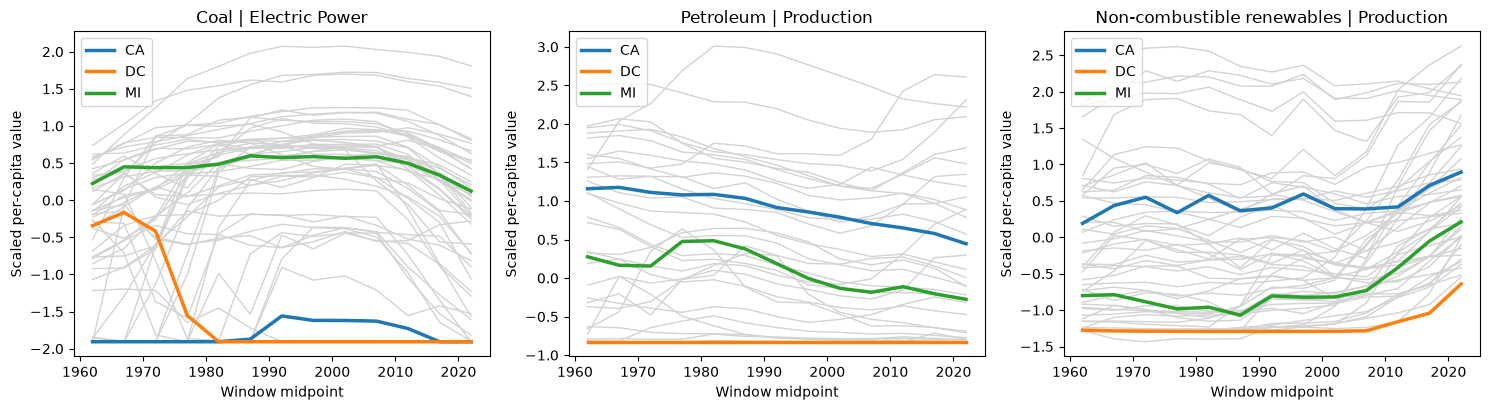

In [13]:
# Example trajectories: all states in grey, a few highlighted
examples = [("CLEIB", ["CA", "DC", "MI"]),
            ("PAPRB", ["CA", "DC", "MI"]),
            ("REPRB", ["CA", "DC", "MI"])]
mid_years = [w + WINDOW_YEARS // 2 for w in windows]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (feat, highlight) in zip(axes, examples):
    paths = traj[feat]
    ax.plot(mid_years, paths.T.values, color="lightgrey", lw=1)
    for state in highlight:
        ax.plot(mid_years, paths.loc[state].values, lw=2.5, label=state)
    ax.set_title(feature_label[feat])
    ax.set_xlabel("Window midpoint")
    ax.set_ylabel("Scaled per-capita value")
    ax.legend()
plt.tight_layout()
plt.show()

In [14]:
# Final Features as Trajectories for each state
windows = sorted(traj.columns.get_level_values("window").unique().tolist())
print("Clustering data:", df.shape[0], "states x", df.shape[1] - 1, "values")
print(f"  = {len(feature_label)} features x {len(windows)} windows")
print("\nFinal Unsupervised Features:")
for code_name, label in feature_label.items():
    print(f"  {code_name}: {label}")

Clustering data: 51 states x 468 values
  = 36 features x 13 windows

Final Unsupervised Features:
  B1PRB: Renewable diesel | Production
  BDACB: Biodiesel | Transportation
  BDEIB: Biodiesel | Electric Power
  BDFDB: Biodiesel | Production
  CLACB: Coal | Transportation
  CLCCB: Coal | Commercial
  CLEIB: Coal | Electric Power
  CLICB: Coal | Industrial
  CLPRB: Coal | Production
  CLRCB: Coal | Residential
  EMACB: Fuel ethanol | Transportation
  EMCCB: Fuel ethanol | Commercial
  EMFDB: Fuel ethanol | Production
  EMICB: Fuel ethanol | Industrial
  RECCB: Non-combustible renewables | Commercial
  REEIB: Non-combustible renewables | Electric Power
  REICB: Non-combustible renewables | Industrial
  REPRB: Non-combustible renewables | Production
  RERCB: Non-combustible renewables | Residential
  NGACB: Natural gas | Transportation
  NGCCB: Natural gas | Commercial
  NGEIB: Natural gas | Electric Power
  NGICB: Natural gas | Industrial
  NGMPB: Natural gas | Production
  NGRCB: Natura

# Step 3: Model Engineering

Exploring model choices.
1. Hierachical Clustering
2. K-Means

Each are graded on the same metrics to determine best model of each family.
* Silhouette (higher is better): how close a state is to its own cluster compared with the nearest other cluster.
* Calinski-Harabasz (higher is better): between-cluster compared with within-cluster variance; it tends to favour small k.
* Davies-Bouldin (lower is better): how much the clusters overlap; it tends to improve as k grows.

There are no true labels, so only these internal measures are available, and none of them is trusted alone (Step 3.4 adds more checks).

In [15]:
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import scipy.cluster.hierarchy as sch

# Set up K values to try and metric
K_VALUES = [2, 3, 4, 5, 6, 7, 8, 9, 10]
METRIC='euclidean'

# Extract processed features
feature_cols = [c for c in df.columns if c not in ID_COLS + [POP_COL]]
X = df[feature_cols].copy()
labels = ""

# Function to print metric scorecard
def metric_scorecard(labels, X, metric=METRIC):
    silhouette = silhouette_score(X, labels, metric=metric)
    calinski_harabasz = calinski_harabasz_score(X, labels)
    davies_bouldin = davies_bouldin_score(X, labels)
    return silhouette, calinski_harabasz, davies_bouldin

# Renumber clusters 0, 1, 2... from largest to smallest (noise stays -1)
def relabel_by_size(labels):
    labels = np.asarray(labels)
    order = pd.Series(labels[labels >= 0]).value_counts().index
    mapping = {old: new for new, old in enumerate(order)}
    mapping[-1] = -1
    return np.array([mapping[x] for x in labels])

## Step 3.1: Hierarachical Clustering

Compare linkages (`ward`, `average`, `complete`, `single`) and k's. Verify with metrics.

Why these linkages: the linkage decides how the distance between two clusters is measured. `single` and `average` linkage join clusters through their nearest points or average distance and tend to *chain*, splitting off one value at a time. `complete` linkage uses the farthest points. `ward` merges the pair that increases the within-cluster variance the least, the same goal as k-means, so it usually gives balanced clusters.

,Linkage,K,Silhouette Score (higher is better),Calinski-Harabasz Score (higher is better),Davies-Bouldin Score (lower is better),Smallest Cluster (states),Largest Cluster (states)
18,average,2,0.403061,4.334803,0.450124,1,50
19,average,3,0.344193,4.184070,0.469195,1,49
20,average,4,0.265314,4.761003,0.752827,1,47
21,average,5,0.258973,4.514565,0.698614,1,46
22,average,6,0.157192,4.127577,0.688114,1,45
23,average,7,0.104930,3.874793,0.677009,1,44
24,average,8,0.090182,3.541744,0.543395,1,44
25,average,9,0.050427,3.612502,0.771074,1,41
26,average,10,0.087469,4.609297,0.805978,1,34
9,complete,2,0.283391,6.608461,1.468333,4,47


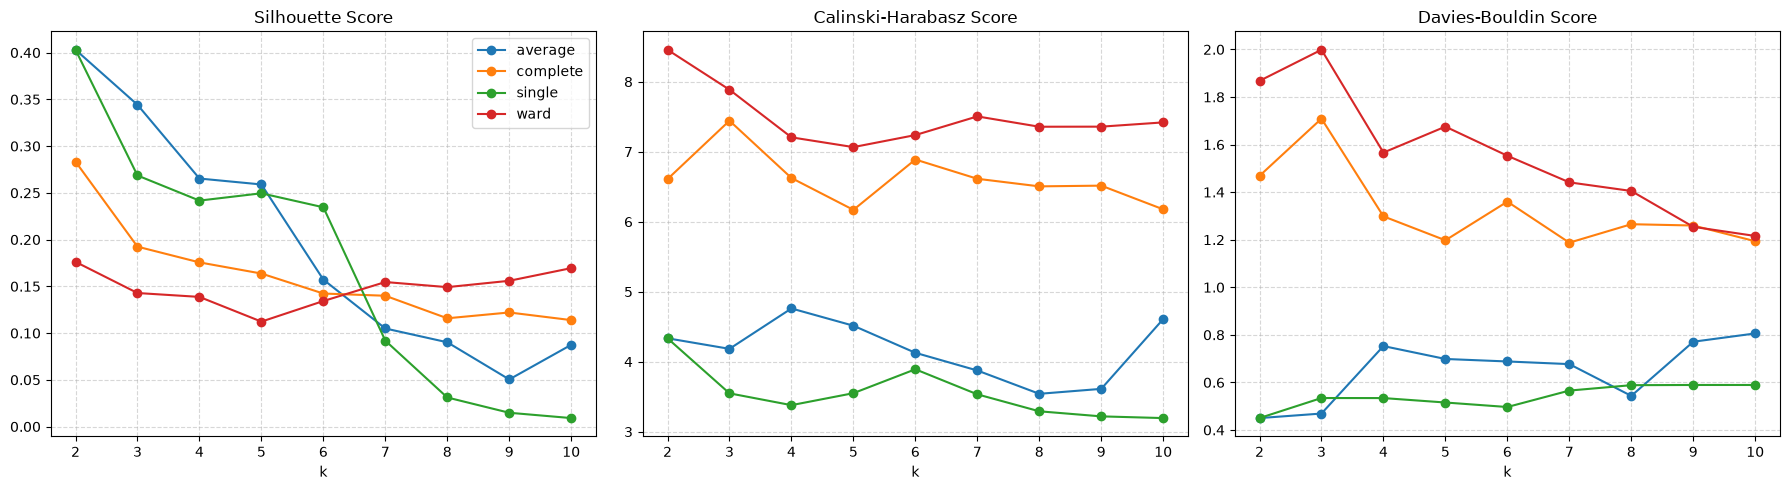

In [16]:
# Hierarchical Clustering
HIER_LINKAGES = ['ward', 'complete', 'average', 'single']
hier_results = []
hier_comparison = ""

for linkage in HIER_LINKAGES:
    for k in K_VALUES:
        try:
            model = AgglomerativeClustering(n_clusters=k, linkage=linkage, metric=METRIC)
            labels = model.fit_predict(X)
            silhouette, calinski_harabasz, davies_bouldin = metric_scorecard(labels, X)

            hier_results.append({
                'Linkage': linkage,
                'K': k,
                'Silhouette Score (higher is better)': silhouette,
                'Calinski-Harabasz Score (higher is better)': calinski_harabasz,
                'Davies-Bouldin Score (lower is better)': davies_bouldin,
                'Smallest Cluster (states)': int(np.bincount(labels).min()),
                'Largest Cluster (states)': int(np.bincount(labels).max())
            })
        except Exception as e:
            print(f"Failed for linkage={linkage}, k={k}: {e}")

# Display as a dataframe
if hier_results:
    hier_comparison = pd.DataFrame(hier_results).sort_values(by=['Linkage', 'K'])
    display(hier_comparison)
else:
    print("No successful clustering configurations were computed.")

# Plot the three evaluation metrics
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics = ["Silhouette Score (higher is better)",
           "Calinski-Harabasz Score (higher is better)",
           "Davies-Bouldin Score (lower is better)"]
for ax, col in zip(axes, metrics):
    for linkage_name, grp in hier_comparison.groupby("Linkage"):
        ax.plot(grp["K"], grp[col], "o-", label=linkage_name)
    ax.set_title(col.split(" (")[0])
    ax.set_xlabel("k")
    ax.grid(True, ls="--", alpha=0.5)
axes[0].legend()
plt.tight_layout()
plt.show()

## Step 3.2: K-Means

Compare init methods (`k-means++` and `random`) and k's. Verify with metrics.

A single k-means run can end in a different local optimum depending on its random start, so every (`init`, `k`) below keeps the best (lowest inertia) of `N_RUNS` independent runs of `N_INIT` restarts.
Why these choices: `k-means++` spreads the starting centers apart, while `random` starts pick arbitrary states, so both are compared, using inertia (the quantity k-means minimizes) as well as the metrics. A single k-means run can end in a different local optimum depending on its random start, so each (`init`, `k`) keeps the best of several runs.

,Init,K,Inertia,Silhouette Score (higher is better),Calinski-Harabasz Score (higher is better),Davies-Bouldin Score (lower is better),Smallest Cluster (states),Largest Cluster (states)
0,k-means++,2,15751.146309,0.140923,10.218944,2.077404,24,27
1,k-means++,3,14004.223829,0.150455,8.623379,1.934598,10,29
2,k-means++,4,12699.492706,0.113614,7.817058,1.921901,4,19
3,k-means++,5,11542.575671,0.124120,7.465830,1.785661,4,15
4,k-means++,6,10339.782014,0.151712,7.569441,1.437450,1,20
5,k-means++,7,9327.438238,0.149241,7.633013,1.385183,1,14
6,k-means++,8,8550.520702,0.158921,7.533001,1.350184,1,16
7,k-means++,9,7796.035528,0.175160,7.569239,1.290370,1,11
8,k-means++,10,7094.718279,0.180293,7.667589,1.142537,1,10
9,random,2,15751.146309,0.140923,10.218944,2.077404,24,27


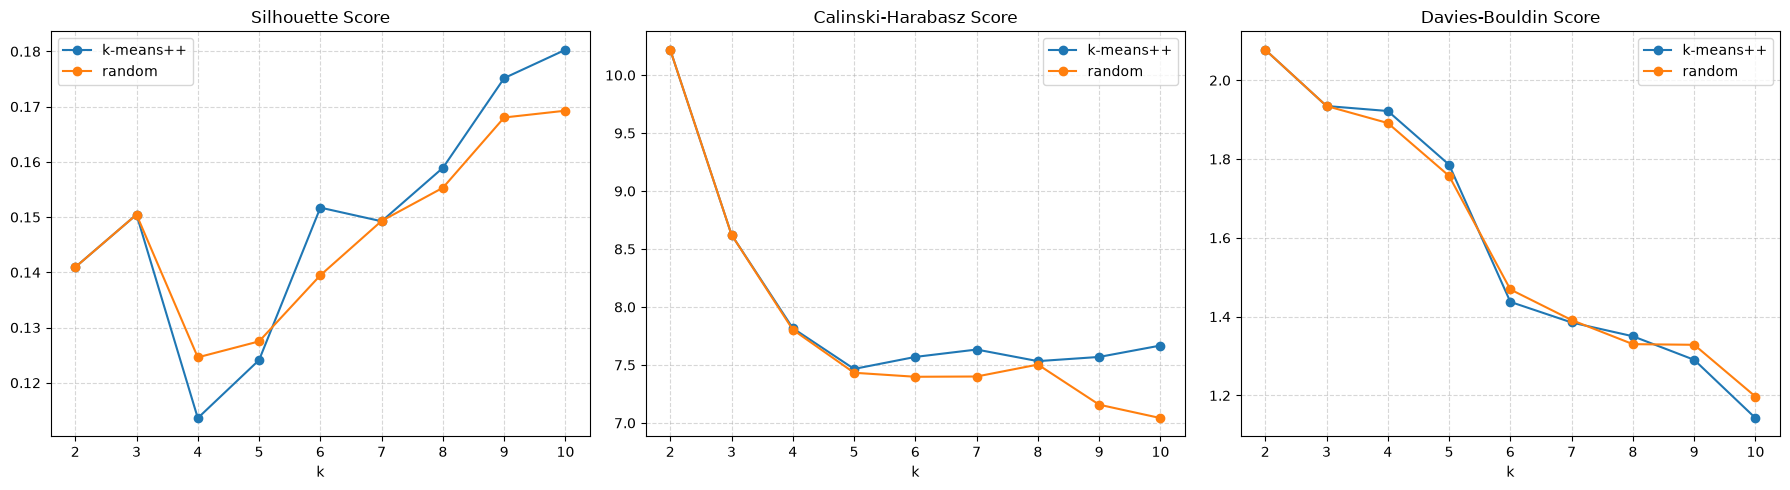

In [17]:
# K-means
K_INIT = ['k-means++', 'random']
N_INIT = 100
N_RUNS = 10
kmeans_results = []
kmeans_labels = {}

for init in K_INIT:
    for k in K_VALUES:
        try:
            # Best (lowest inertia) of N_RUNS independent runs
            runs = [KMeans(init=init, n_clusters=k, random_state=SEED + r, n_init=N_INIT).fit(X)
                    for r in range(N_RUNS)]
            model = min(runs, key=lambda m: m.inertia_)
            labels = model.labels_
            kmeans_labels[(init, k)] = labels
            silhouette, calinski_harabasz, davies_bouldin = metric_scorecard(labels, X)

            kmeans_results.append({
                'Init': init,
                'K': k,
                'Inertia': model.inertia_,
                'Silhouette Score (higher is better)': silhouette,
                'Calinski-Harabasz Score (higher is better)': calinski_harabasz,
                'Davies-Bouldin Score (lower is better)': davies_bouldin,
                'Smallest Cluster (states)': int(np.bincount(labels).min()),
                'Largest Cluster (states)': int(np.bincount(labels).max())
            })
        except Exception as e:
            print(f"Failed for KMeans, k={k}: {e}")

# Display results
if kmeans_results:
    df_kmeans = pd.DataFrame(kmeans_results).sort_values(by=['Init', 'K'])
    display(df_kmeans)
else:
    print("No K-Means results were generated.")

# Plot the three evaluation metrics
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["Silhouette Score (higher is better)",
                          "Calinski-Harabasz Score (higher is better)",
                          "Davies-Bouldin Score (lower is better)"]):
    for init_name, grp in df_kmeans.groupby("Init"):
        ax.plot(grp["K"], grp[col], "o-", label=init_name)
    ax.set_title(col.split(" (")[0])
    ax.set_xlabel("k")
    ax.grid(True, ls="--", alpha=0.5)
    ax.legend()
plt.tight_layout()
plt.show()

## Step 3.3: Hyperparameter Tuning

Based on results from 3.1 and 3.2, select best linkage/init then compare k's and select the final value.

In [18]:
BEST_LINKAGE = "ward"
BEST_INIT = "k-means++"

from sklearn.metrics import adjusted_rand_score

# Full-data solutions for every k
X_arr = X.values
solutions = {"Hierarchical": {}, "K-Means": {}}
for k in K_VALUES:
    solutions["Hierarchical"][k] = relabel_by_size(
        AgglomerativeClustering(n_clusters=k, linkage=BEST_LINKAGE).fit_predict(X_arr))
    solutions["K-Means"][k] = relabel_by_size(kmeans_labels[(BEST_INIT, k)])

# How each method re-clusters a subsample (k-means is lighter here because it is repeated many times)
fits = {"Hierarchical": lambda p, k: AgglomerativeClustering(n_clusters=k, linkage=BEST_LINKAGE).fit_predict(p),
        "K-Means": lambda p, k: KMeans(n_clusters=k, init=BEST_INIT, n_init=N_INIT, random_state=SEED).fit_predict(p)}

card_rows = []
for family, fit in fits.items():
    for k in K_VALUES:
        full = solutions[family][k]
        rng = np.random.default_rng(SEED)
        aris, jacc = [], [[] for _ in range(k)]
        for _ in range(30):
            # Re-cluster a random 80% of the states ...
            idx = np.sort(rng.choice(len(X_arr), int(0.8 * len(X_arr)), replace=False))
            sub = np.asarray(fit(X_arr[idx], k))
            # Compare with the full solution on the same states (ARI) ...
            aris.append(adjusted_rand_score(full[idx], sub))
            # ... and find the best match of every cluster (Jaccard)
            for c in range(k):
                ref = set(idx[full[idx] == c])
                if ref:
                    jacc[c].append(max(len(ref & set(idx[sub == d])) / len(ref | set(idx[sub == d]))
                                       for d in range(k)))
        silhouette, calinski_harabasz, davies_bouldin = metric_scorecard(full, X_arr)
        sizes = np.bincount(full)
        card_rows.append({"Family": family, "K": k, 
                          "Silhouette": silhouette, 
                          "Calinski-Harabasz": calinski_harabasz, 
                          "Davies-Bouldin": davies_bouldin,
                          "Stability (ARI)": np.mean(aris),
                          "Least Stable Cluster (Jaccard)": min(np.mean(j) for j in jacc if j),
                          "Agreement (ARI)": adjusted_rand_score(
                              solutions["Hierarchical"][k], solutions["K-Means"][k]),
                          "Clusters with 1-2 states": int((sizes <= 2).sum()),
                          "Cluster sizes": sorted(sizes.tolist(), reverse=True)})
scorecard = pd.DataFrame(card_rows)

for family in ["Hierarchical", "K-Means"]:
    print(family)
    print(scorecard[scorecard["Family"] == family].drop(columns="Family")
          .set_index("K").round(3).to_string())

Hierarchical
    Silhouette  Calinski-Harabasz  Davies-Bouldin  Stability (ARI)  Least Stable Cluster (Jaccard)  Agreement (ARI)  Clusters with 1-2 states                    Cluster sizes
K                                                                                                                                                                             
2        0.176              8.456           1.868            0.483                           0.624            0.229                         0                         [40, 11]
3        0.143              7.886           1.999            0.778                           0.776            0.816                         0                     [30, 11, 10]
4        0.139              7.205           1.566            0.765                           0.587            0.405                         1                  [30, 10, 10, 1]
5        0.112              7.066           1.675            0.520                           0.503            0.

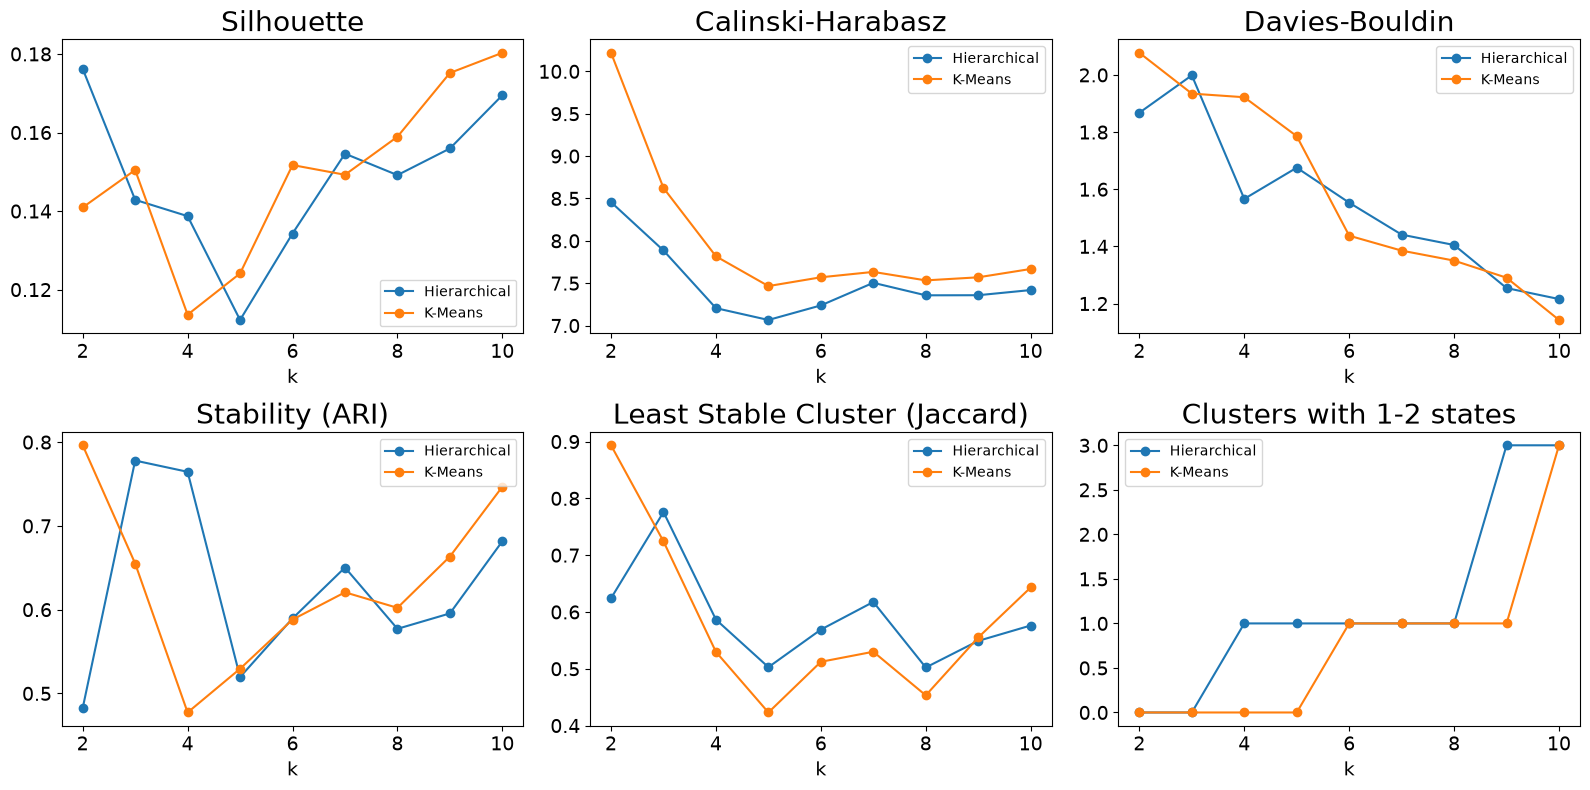

In [19]:
# Plot all metrics
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), ["Silhouette", "Calinski-Harabasz", "Davies-Bouldin",
                                  "Stability (ARI)", "Least Stable Cluster (Jaccard)",
                                  "Clusters with 1-2 states"]):
    for family, grp in scorecard.groupby("Family"):
        ax.plot(grp["K"], grp[col], "o-", label=family)
    ax.set_title(col, fontsize=20)
    ax.set_xlabel("k", fontsize=14)
    ax.tick_params(axis='both', labelsize=14)
    ax.legend()
plt.tight_layout()
plt.show()

#fig, ax = plt.subplots(figsize=(16/3, 8/3))
agree = scorecard[scorecard["Family"] == "Hierarchical"]
ax.plot(agree["K"], agree["Agreement (ARI)"], "o-", color="tab:green")
ax.set_title(f"Agreement Between \nHierarchical and K-Means (ARI)")
ax.set_xlabel("k")
ax.set_ylim(0, 1)
plt.show()

In [20]:
# Choices made from Step 3
BEST_HIER_K = 7
BEST_KMEANS_K = 7
print(f"Hierarchical: {BEST_LINKAGE} linkage, k = {BEST_HIER_K}")
print(f"K-Means     : {BEST_INIT}, k = {BEST_KMEANS_K}")

# Print scorecard comparison specifically for k=7
print("\nScorecard Comparison for k = 7:")
display(scorecard[scorecard["K"] == 7].round(3))

Hierarchical: ward linkage, k = 7
K-Means     : k-means++, k = 7

Scorecard Comparison for k = 7:


,Family,K,Silhouette,Calinski-Harabasz,Davies-Bouldin,Stability (ARI),Least Stable Cluster (Jaccard),Agreement (ARI),Clusters with 1-2 states,Cluster sizes
5,Hierarchical,7,0.155,7.504,1.441,0.650,0.618,0.707,1,"[15, 15, 7, 7, 3, 3, 1]"
14,K-Means,7,0.149,7.633,1.385,0.621,0.530,0.707,1,"[14, 12, 9, 7, 5, 3, 1]"


# Step 4: Cluster Results

Analysis of best model from each family in Step 3.

1. Silhouette Plot
2. PCA Scatter Plot
3. Choropleth Map
4. Final Clustering and Dendrogram

## Step 4.1: Silhouette Plot

The silhouette of every state (how close it is to its own cluster compared with the nearest other cluster), grouped by cluster. States with negative values are closer to another cluster than to their own.

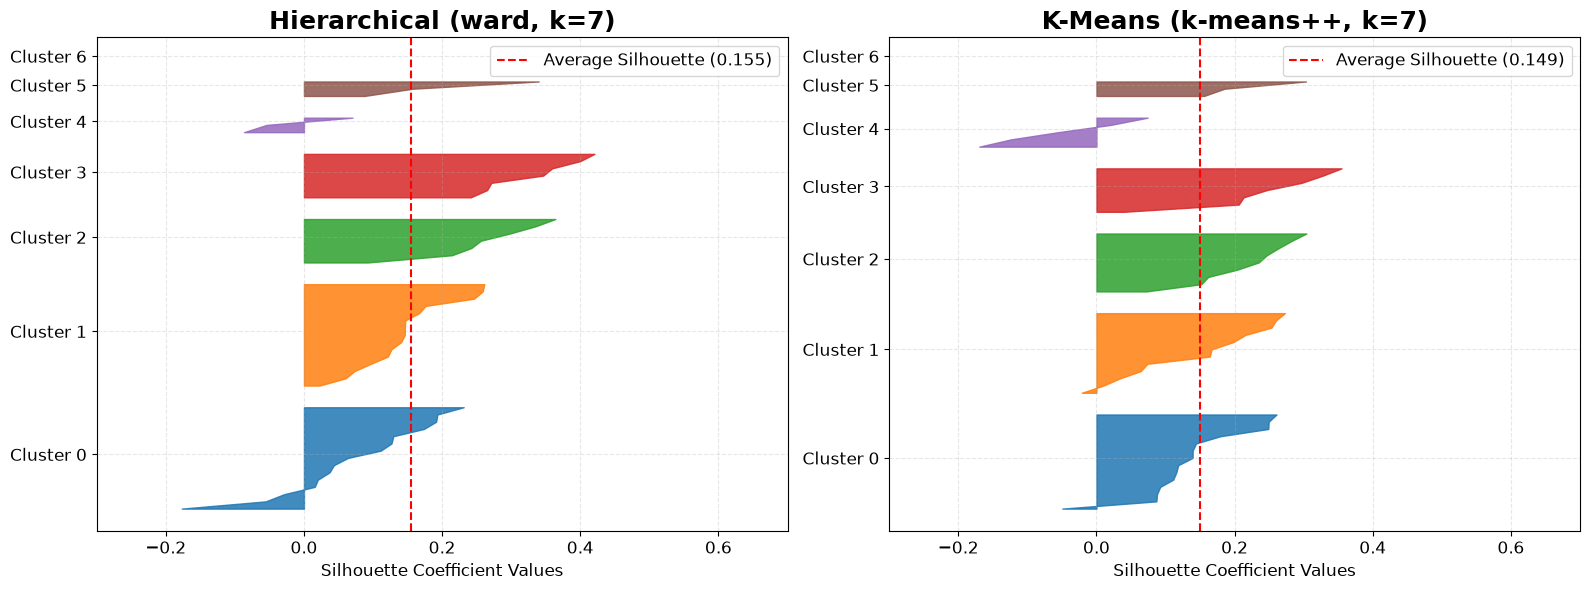

In [21]:
from sklearn.metrics import silhouette_samples

models = {
    f"Hierarchical ({BEST_LINKAGE}, k={BEST_HIER_K})": solutions["Hierarchical"][BEST_HIER_K],
    f"K-Means ({BEST_INIT}, k={BEST_KMEANS_K})": solutions["K-Means"][BEST_KMEANS_K],
}

# Plot Silhoutte Scores
palette = sns.color_palette("tab10", 10)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (name, labels) in zip(axes, models.items()):
    keep_mask = labels >= 0
    values = silhouette_samples(X_arr[keep_mask], labels[keep_mask])
    y_low = 2
    ticks = []
    tick_labels = []

    for cluster in np.unique(labels[keep_mask]):
        vals = np.sort(values[labels[keep_mask] == cluster])
        y_span = np.arange(y_low, y_low + len(vals))
        ax.fill_betweenx(y_span, 0, vals,
                         color=palette[cluster % 10], alpha=0.85)

        ticks.append(y_low + len(vals) / 2)
        tick_labels.append(f"Cluster {cluster}")
        y_low += len(vals) + 2

    ax.axvline(values.mean(), color="red", ls="--", label=f"Average Silhouette ({values.mean():.3f})")
    ax.set_title(f"{name}", fontsize=18, fontweight='bold')
    ax.set_xlabel("Silhouette Coefficient Values", fontsize=12)
    ax.set_yticks(ticks)
    ax.set_yticklabels(tick_labels, fontsize=12)
    ax.tick_params(axis='x', labelsize=12) 
    ax.set_xlim([-0.3, 0.7])
    ax.grid(True, ls="--", alpha=0.3)
    ax.legend(loc="upper right", fontsize=12)

plt.tight_layout()
plt.show()

## Step 4.2: PCA Scatter Plot

The values of every state are reduced to two principal components, only to draw the clusters in 2-D.

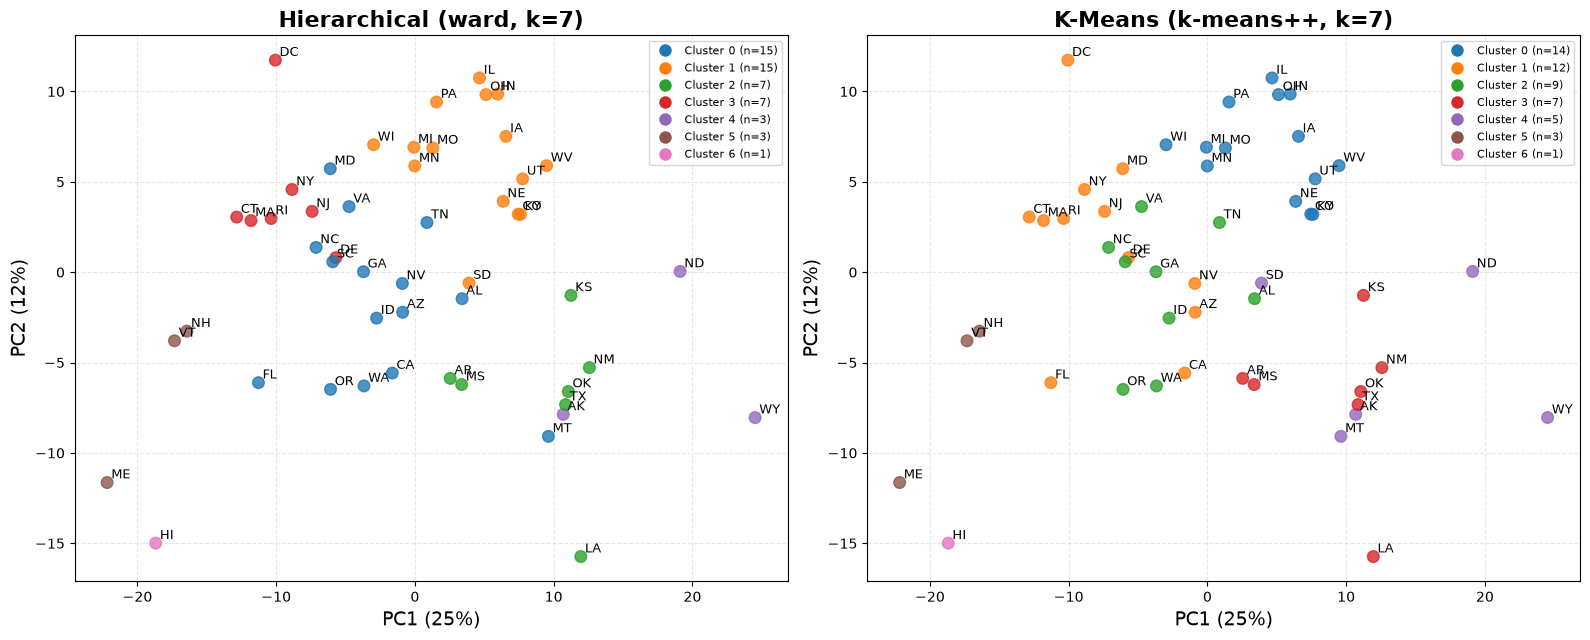

In [22]:
from sklearn.decomposition import PCA

# Plot clusters onto PCA space
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_arr)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (name, labels) in zip(axes, models.items()):
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=[palette[c % 10] for c in labels], s=70, alpha=0.8)

    # Add legend back by creating proxy artists for unique clusters
    unique_labels = np.unique(labels)
    legend_elements = [
        plt.Line2D([0], [0], marker='o', color='w',
                   markerfacecolor=palette[c % 10], markersize=10,
                   label=f"Cluster {c} (n={(labels == c).sum()})")
        for c in unique_labels if c >= 0
    ]
    ax.legend(handles=legend_elements, loc="best", fontsize=8)

    for i, state in enumerate(states):
        ax.annotate(state, X_pca[i], fontsize=9, xytext=(3, 3), textcoords="offset points")

    ax.set_title(name, fontsize=16, fontweight='bold')
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", fontsize=14)
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})", fontsize=14)
    ax.grid(True, ls="--", alpha=0.3)

plt.tight_layout()
plt.show()

## Step 4.3: Choropleth Map

State outlines are read from a public GeoJSON file (the only data from outside the two input files, used only to draw the map). If it cannot be downloaded, a tile map (one square per state) is drawn instead.

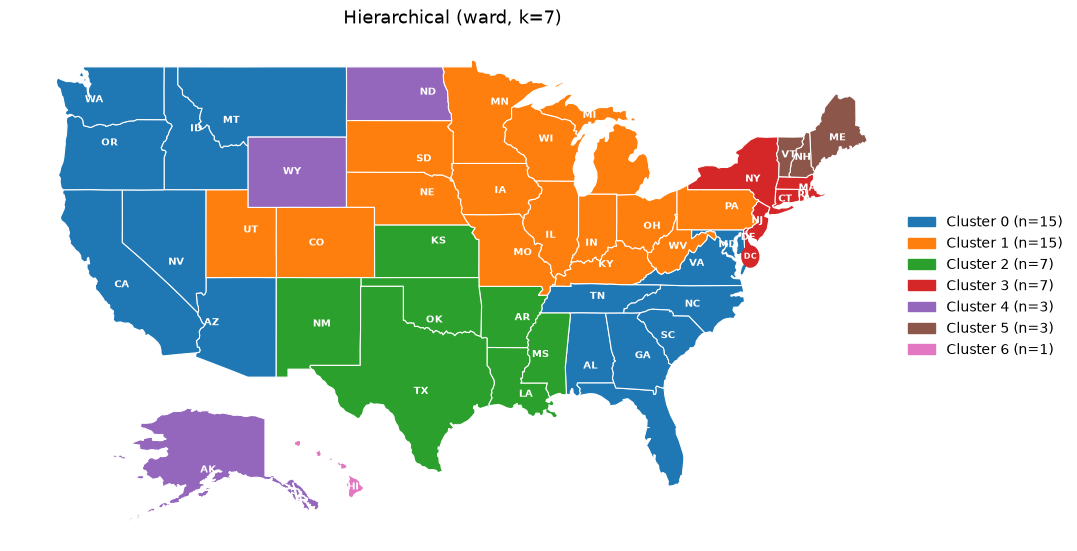

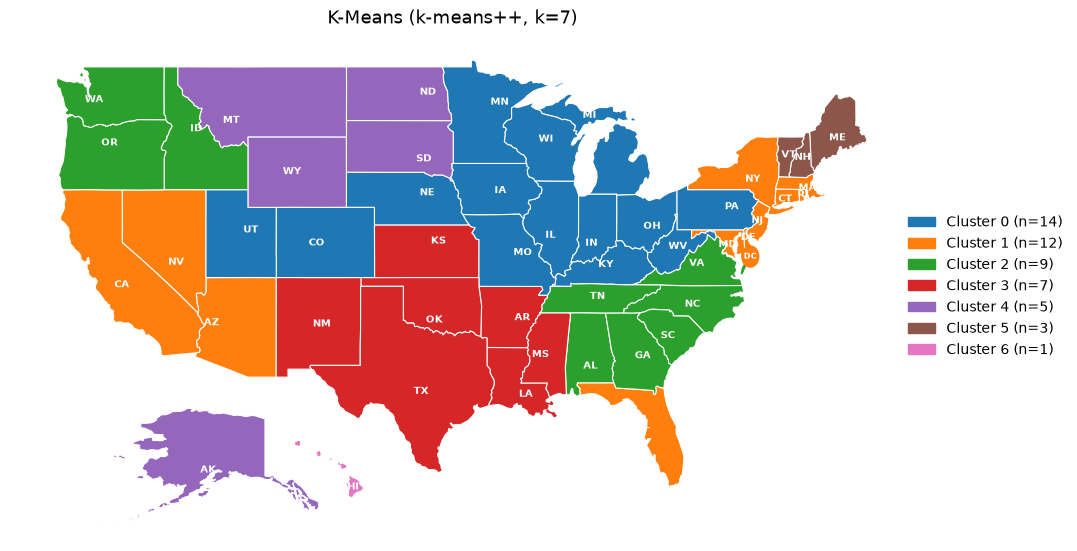

In [23]:
from matplotlib.collections import PatchCollection
from matplotlib.patches import Circle, Patch, Polygon
from pathlib import Path
import urllib.request
import json

GEOJSON_URL = ("https://raw.githubusercontent.com/python-visualization/"
               "folium/main/examples/data/us-states.json")
GEOJSON_FILE = Path(OUTPUT_DIR) / "../Other/us-states.json"

# Fallback layout: one tile per state (row, column).
TILE_GRID = {
    "AK": (0, 0), "ME": (0, 10), "WI": (1, 5), "VT": (1, 9), "NH": (1, 10),
    "WA": (2, 0), "ID": (2, 1), "MT": (2, 2), "ND": (2, 3), "MN": (2, 4),
    "IL": (2, 5), "MI": (2, 6), "NY": (2, 8), "MA": (2, 9),
    "OR": (3, 0), "NV": (3, 1), "WY": (3, 2), "SD": (3, 3), "IA": (3, 4),
    "IN": (3, 5), "OH": (3, 6), "PA": (3, 7), "NJ": (3, 8), "CT": (3, 9),
    "RI": (3, 10), "CA": (4, 0), "UT": (4, 1), "CO": (4, 2), "NE": (4, 3),
    "MO": (4, 4), "KY": (4, 5), "WV": (4, 6), "VA": (4, 7), "MD": (4, 8),
    "DE": (4, 9), "AZ": (5, 1), "NM": (5, 2), "KS": (5, 3), "AR": (5, 4),
    "TN": (5, 5), "NC": (5, 6), "SC": (5, 7), "DC": (5, 8), "OK": (6, 3),
    "LA": (6, 4), "MS": (6, 5), "AL": (6, 6), "GA": (6, 7), "HI": (7, 0),
    "TX": (7, 3), "FL": (7, 8)}

# Read the state outlines from disk, or download them once
try:
    if not GEOJSON_FILE.exists():
        with urllib.request.urlopen(GEOJSON_URL, timeout=20) as reply:
            GEOJSON_FILE.write_bytes(reply.read())
    geo = json.loads(GEOJSON_FILE.read_text())
except Exception as error:
    print("Could not load state outlines:", error)
    geo = None


def draw_map(labels, title, filename, cluster_names=None):
    """Colour every state by its cluster id (noise = grey) and display the map."""
    by_state = dict(zip(states, labels))
    colors = {s: (palette[c % 10] if c >= 0 else "lightgrey") for s, c in by_state.items()}
    fig, ax = plt.subplots(figsize=(15, 7.5))
    if geo is not None:
        patches, face = [], []
        for feature in geo["features"]:
            state = feature["id"]
            polys = feature["geometry"]["coordinates"]
            if feature["geometry"]["type"] == "Polygon":
                polys = [polys]
            rings = []
            for poly in polys:
                ring = np.asarray(poly[0], dtype=float)
                if state == "AK":             # Shrink/move Alaska into an inset
                    ring = (ring - [-150, 64]) * 0.35 + [-113, 27]
                elif state == "HI":           # Move Hawaii into an inset
                    ring = ring + [52, 5.5]
                rings.append(ring)
                patches.append(Polygon(ring, closed=True))
                face.append(colors[state])
            x, y = max(rings, key=len).mean(axis=0)
            ax.text(x, y, state, ha="center", va="center", fontsize=7,
                    color="white", weight="bold")
        ax.add_collection(PatchCollection(patches, facecolor=face, edgecolor="white", lw=0.8))
        ax.add_patch(Circle((-75.3, 38.2), 0.6, color=colors["DC"]))  # DC Circle
        ax.text(-75.3, 38.2, "DC", ha="center", va="center", fontsize=6, color="white", weight="bold")
        ax.set_xlim(-128, -65)
        ax.set_ylim(22, 51)
        ax.set_aspect(1.25)

    # Offline fallback: tile map
    else:
        for state, (row, col) in TILE_GRID.items():
            ax.add_patch(plt.Rectangle((col, -row), 0.92, 0.92, color=colors[state]))
            ax.text(col + 0.46, -row + 0.46, state, ha="center", va="center",
                    color="white", weight="bold")
        ax.set_xlim(-0.2, 11.2)
        ax.set_ylim(-7.2, 1.2)
        ax.set_aspect(1)
    ax.axis("off")
    ax.set_title(title, fontsize=13)
    counts = pd.Series(labels).value_counts()
    handles = [Patch(color=palette[c % 10] if c >= 0 else "lightgrey",
                     label=((f"C{c}: {cluster_names[c]}" if cluster_names else f"Cluster {c}")
                            if c >= 0 else "Noise") + f" (n={counts[c]})")
               for c in sorted(counts.index)]
    ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5),
              fontsize=10, frameon=False)
    fig.subplots_adjust(left=0.01, right=0.60, top=0.93, bottom=0.02)
    # Commented out to prevent saving each map to a file
    # fig.savefig(OUTPUT_DIR / filename, dpi=130)
    plt.show()

# Generate maps for the two models
for (name, labels), slug in zip(models.items(), ["hierarchical", "kmeans"]):
    draw_map(labels, name, f"map_{slug}.png")

## Step 4.4: Final Clustering and Dendrogram

Hierarchical (Ward, k = 7) is used as the final model. Its silhouette is similar to k-means, but its least stable cluster is more stable, it does not depend on a random start, and its tree shows exactly which states join. K-means has the advantage of no cluster with only 1-2 states. To use k-means instead, change `FINAL_MODEL` to the K-Means entry of models.

In [24]:
# Final Clustering
FINAL_MODEL = f"Hierarchical ({BEST_LINKAGE}, k={BEST_HIER_K})"
final_labels = models[FINAL_MODEL]
FINAL_K = int(final_labels.max()) + 1
cluster_of_state = dict(zip(states, final_labels))
print("Final model:", FINAL_MODEL)
for cid in range(FINAL_K):
    members = [s for s, l in zip(states, final_labels) if l == cid]
    print(f"C{cid} ({len(members)} states): {', '.join(members)}")

Final model: Hierarchical (ward, k=7)
C0 (15 states): AL, AZ, CA, FL, GA, ID, MD, MT, NC, NV, OR, SC, TN, VA, WA
C1 (15 states): CO, IA, IL, IN, KY, MI, MN, MO, NE, OH, PA, SD, UT, WI, WV
C2 (7 states): AR, KS, LA, MS, NM, OK, TX
C3 (7 states): CT, DC, DE, MA, NJ, NY, RI
C4 (3 states): AK, ND, WY
C5 (3 states): ME, NH, VT
C6 (1 states): HI


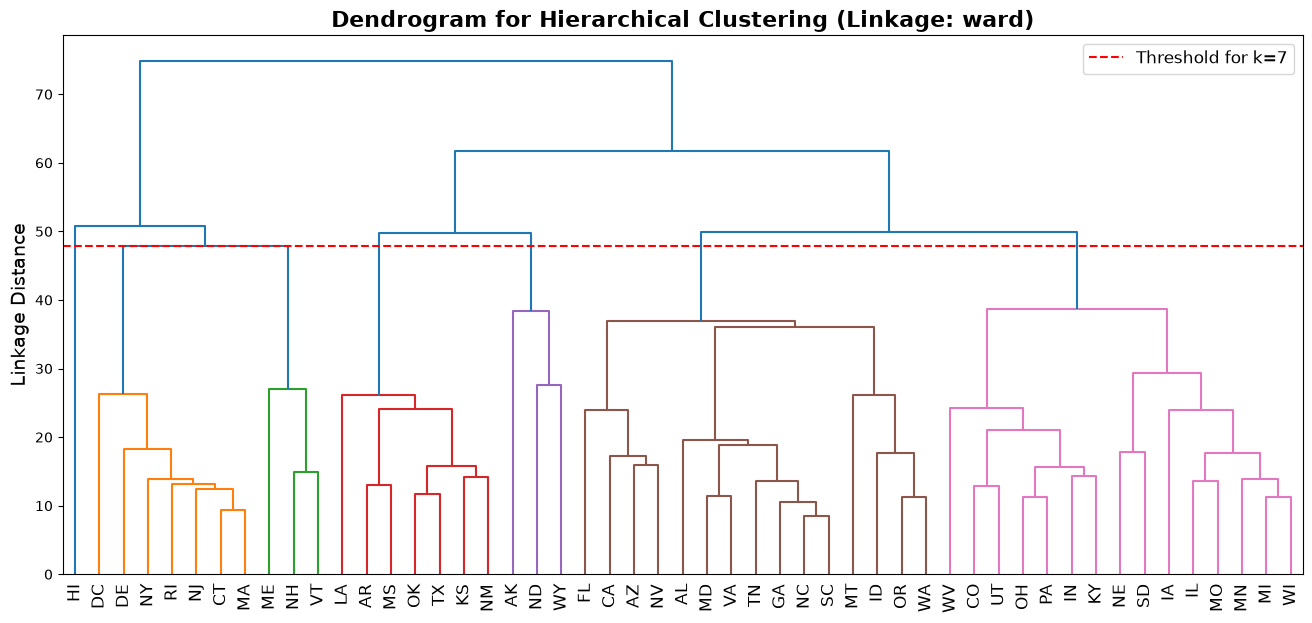

In [25]:
# Dendrogram for Hierarchical Clustering
fig, (ax1) = plt.subplots(1, 1, figsize=(16, 7))
Z = sch.linkage(X_arr, method=BEST_LINKAGE, metric=METRIC)
threshold = Z[-BEST_HIER_K+1, 2]
sch.dendrogram(
    Z,
    labels=states,
    leaf_rotation=90.,
    leaf_font_size=12.,
    color_threshold=threshold,
    ax=ax1
)

ax1.axhline(y=threshold, color='r', linestyle='--', label=f'Threshold for k={BEST_HIER_K}')
ax1.set_title(f"Dendrogram for Hierarchical Clustering (Linkage: {BEST_LINKAGE})", fontsize=16, fontweight='bold')
ax1.set_ylabel("Linkage Distance", fontsize=14)
ax1.legend(fontsize=12)

# Step 5: Conclusions

1. Sensitivity Analysis
2. Cluster Definitions
3. Export

## Step 5.1: Sensitivity Analysis

How much does the final result change when one choice of the analysis is changed? Each experiment repeats the whole feature engineering of Step 2 with one change, re-runs the final method on the new data and compares the grouping with the final one using the Adjusted Rand Index (ARI): 1 means the same grouping of states, and values near 0 mean unrelated groupings. (Silhouettes from different feature sets cannot be compared, so ARI is used.)

The function below repeats Step 2 from the untouched data `df_raw`. A check confirms that, with its default settings, it gives exactly the same data as Step 2.


In [26]:
# Perform Step 2 with changes
cat2 = df_categories.set_index("MSN Code")['Category 2'].to_dict()
raw_cols = [c for c in df_raw.columns if c not in ID_COLS + [POP_COL]]

def make_features(data=df_raw, empty=EMPTY_THRESHOLD, combine=("Non-Combustible",),
                  drop_types=(), drop_sectors=(), window=WINDOW_YEARS, per_capita=True, log=True):
    """Repeat Step 2 on `data` and return one row per state (index = State)."""
    d = data.copy()

    # 2.1: More Cleaning: Duplicated and Empty Features
    cols = [c for c in raw_cols if c in d.columns]
    dup_mask = d[cols].T.duplicated(keep='first')
    cols = [c for c in cols if not dup_mask.get(c, False)]

    if empty is not None and empty > 0:
        cols = [c for c in cols if ((d[c] != 0).sum() / len(d)) >= empty]

    # 2.2: Filter by types and sectors; Combine Renewables
    sector = {c: SECTOR_CODES[c[2:4]] for c in cols}
    cols = [c for c in cols
            if cat2.get(c, "Non-Combustible") not in drop_types and sector[c] not in drop_sectors]
    new_name = {}
    for c in cols:
        name = "RE" + c[2:] if cat2.get(c, "Non-Combustible") in combine else c
        if name.startswith("RE"):
            sect = name[2:4]
            if sect in ["PR", "MP", "FD"]:
                name = name[:2] + "PR" + name[4:]
            elif sect in ["EG", "EI"]:
                name = name[:2] + "EI" + name[4:]
        new_name[c] = name

    # 2.2: Trajectory Windows
    d = pd.concat([d[ID_COLS + [POP_COL]], d[cols].T.groupby(new_name).sum().T], axis=1)
    d["Year"] = START_YEAR + ((d["Year" ] - START_YEAR) // window) * window
    d = d.groupby(ID_COLS, as_index=False).mean()

    # 2.2: Scale & Per Capita
    feats = [c for c in d.columns if c not in ID_COLS + [POP_COL]]
    if per_capita:
        d[feats] = d[feats].div(d[POP_COL], axis=0)
    d = d.drop(columns=[POP_COL])

    # 2.3: Pre-Processing Log and Scaling
    if log:
        d[feats] = d[feats].apply(np.log1p)
    scaler = StandardScaler()
    d[feats] = scaler.fit_transform(d[feats])

    # 2.3: Pivot to Trajectory format
    wide = d.pivot(index="State", columns="Year")
    wide.columns = [f"{f}_{y}" for f, y in wide.columns]
    return wide

# Verification
check = make_features()
reference = df.set_index("State")
print("Same columns as Step 2:", sorted(check.columns) == sorted(reference.columns))
print("Same values as Step 2 :", bool(np.allclose(check[reference.columns].values, reference.values)))


Same columns as Step 2: True
Same values as Step 2 : True


                               Experiment  Values per state  ARI vs baseline  Silhouette (own data)  Smallest cluster  Largest cluster
                   Baseline (final model)               468            1.000                  0.155                 1               15
            Do NOT combine the renewables               637            0.465                  0.124                 1               22
Combine ALL renewables (also combustible)               325            0.606                  0.184                 2               21
   Keep columns with >= 20% non-zero only               442            0.963                  0.163                 2               15
Keep all columns (no empty-column filter)               507            0.958                  0.146                 1               15
                       Window = 1 year(s)              2340            1.000                  0.151                 1               15
                       Window = 2 year(s)              

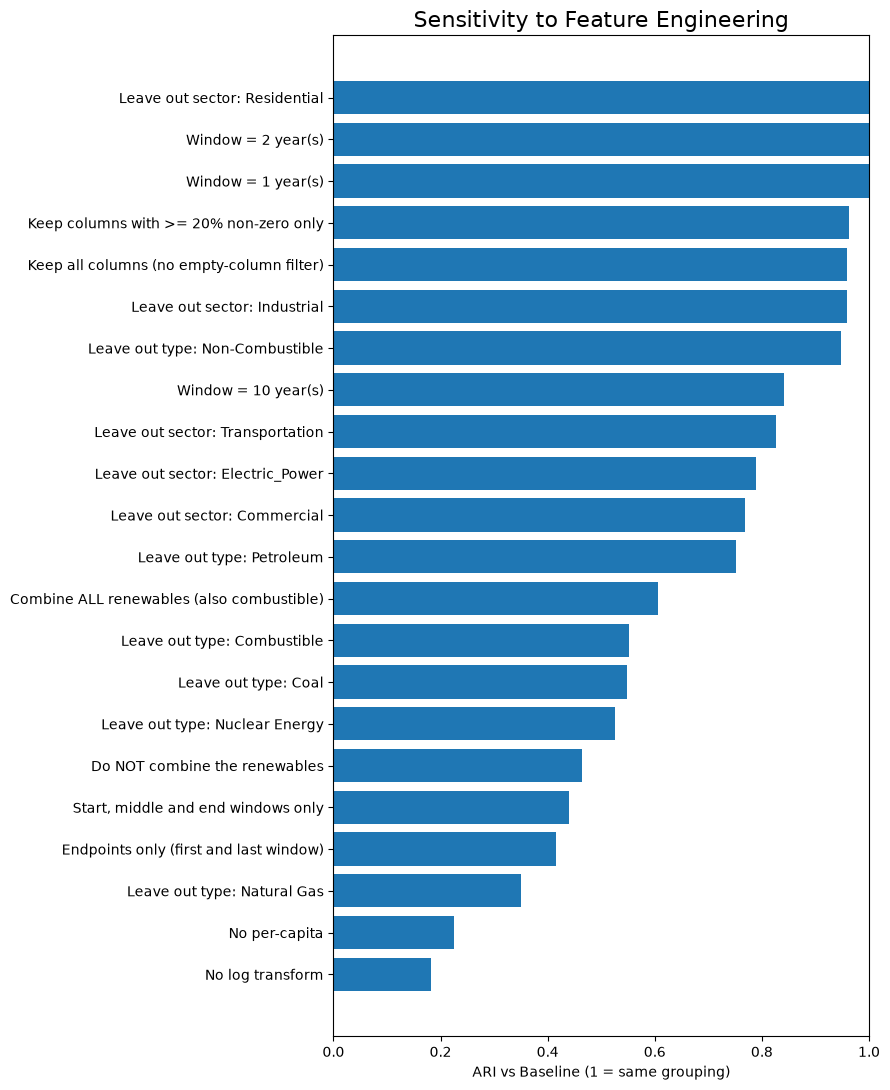

In [27]:
def fit_final(points, k=FINAL_K):
    """Re-run the final model on a new data matrix."""
    clean_points = np.nan_to_num(np.asarray(points), nan=0.0)
    return AgglomerativeClustering(n_clusters=k, linkage=BEST_LINKAGE).fit_predict(clean_points)


baseline = pd.Series(final_labels, index=states)

# The experiments: every entry is a new data matrix
experiments = {}
experiments["Do NOT combine the renewables"] = make_features(combine=())
experiments["Combine ALL renewables (also combustible)"] = make_features(combine=("Non-Combustible", "Combustible"))
experiments["Keep columns with >= 20% non-zero only"] = make_features(empty=0.20)
experiments["Keep all columns (no empty-column filter)"] = make_features(empty=-1)
for w in (1, 2, 10):
    experiments[f"Window = {w} year(s)"] = make_features(window=w)
experiments["No per-capita"] = make_features(per_capita=False)
experiments["No log transform"] = make_features(log=False)

# Fewer time points from the baseline data
window_of = check.columns.str.rsplit("_", n=1).str[1].astype(int)
experiments["Start, middle and end windows only"] = check.loc[:, window_of.isin(
    [windows[0], windows[len(windows) // 2], windows[-1]])]
experiments["Endpoints only (first and last window)"] = check.loc[:, window_of.isin([windows[0], windows[-1]])]

# Leave out one energy type / one sector at a time
for t in ["Coal", "Petroleum", "Natural Gas", "Nuclear Energy", "Combustible", "Non-Combustible"]:
    experiments[f"Leave out type: {t}"] = make_features(drop_types=(t,))
for s in ["Transportation", "Commercial", "Electric_Power", "Industrial", "Residential"]:
    experiments[f"Leave out sector: {s}"] = make_features(drop_sectors=(s,))

# Results
rows = [{"Experiment": "Baseline (final model)", "Values per state": X_arr.shape[1],
         "ARI vs baseline": 1.0, "Silhouette (own data)": silhouette_score(X_arr, final_labels),
         "Smallest cluster": int(np.bincount(final_labels).min()),
         "Largest cluster": int(np.bincount(final_labels).max())}]
for name, data in experiments.items():
    # Safeguard evaluation against NaNs by replacing them with 0.0
    clean_data_values = np.nan_to_num(data.values, nan=0.0)
    labels = fit_final(clean_data_values)
    rows.append({"Experiment": name, "Values per state": data.shape[1],
                 "ARI vs baseline": adjusted_rand_score(final_labels, labels),
                 "Silhouette (own data)": silhouette_score(clean_data_values, labels),
                 "Smallest cluster": int(np.bincount(labels).min()),
                 "Largest cluster": int(np.bincount(labels).max())})
sens = pd.DataFrame(rows)
print(sens.round(3).to_string(index=False))

# Visualize
plot = sens.iloc[1:].sort_values("ARI vs baseline")
fig, ax = plt.subplots(figsize=(9, 11))
ax.barh(plot["Experiment"], plot["ARI vs baseline"],
        color=["tab:blue" for n in plot["Experiment"]])
ax.set_xlim(0, 1)
ax.set_xlabel("ARI vs Baseline (1 = same grouping)")
ax.set_title("Sensitivity to Feature Engineering", fontsize=16)
ax.tick_params(axis="y", labelsize=10)
plt.tight_layout()
plt.show()

## Step 5.2: Cluster Definitions

The clusters of the final model are described from the data. Names are written by hand after reading the profiles; they describe the energy types and sectors only.
The amounts table gives interpretable numbers (million Btu per person), and the borderline states show where the clusters are least clear. Names are written by hand because they depend on reading the profiles.

In [28]:
# Written description of every cluster: the features that are highest and lowest over the whole period,
# the features that define the first and the last window, and the largest changes.
def top_items(series, n=4, ascending=False):
    """Name and value of the n largest (or smallest) entries."""
    picked = series.sort_values(ascending=ascending).head(n)
    return "; ".join(f"{feature_label[f]} ({v:+.1f})" for f, v in picked.items())

# Average trajectory of each cluster (the cluster "centroid")
centroids = traj.groupby(final_labels).mean()
level = centroids.T.groupby(level="feature").mean().T                       # mean over all windows
change = centroids.xs(windows[-1], axis=1, level="window") - centroids.xs(windows[0], axis=1, level="window")
sizes = np.bincount(final_labels)

rows = []
for cid in range(FINAL_K):
    members = [s for s, l in zip(states, final_labels) if l == cid]
    start = centroids.loc[cid].xs(windows[0], level="window")
    end = centroids.loc[cid].xs(windows[-1], level="window")
    rows.append({"cluster_id": cid, "n_states": len(members), "states": ", ".join(members),
                 "above_average_overall": top_items(level.loc[cid]),
                 "below_average_overall": top_items(level.loc[cid], 3, True),
                 f"most_distinctive_in_{windows[0]}": top_items(start, 3),
                 f"most_distinctive_in_{windows[-1]}": top_items(end, 3),
                 "largest_increases": top_items(change.loc[cid], 3),
                 "largest_decreases": top_items(change.loc[cid], 3, True)})
descriptions = pd.DataFrame(rows)
for _, row in descriptions.iterrows():
    print(f"=== Cluster {row['cluster_id']} ({row['n_states']} states) ===")
    for label, value in row.drop(["cluster_id", "n_states"]).items():
        print(f"  {label:28s}: {value}")

=== Cluster 0 (15 states) ===
  states                      : AL, AZ, CA, FL, GA, ID, MD, MT, NC, NV, OR, SC, TN, VA, WA
  above_average_overall       : Non-combustible renewables | Electric Power (+0.6); Non-combustible renewables | Production (+0.6); Wood and waste | Industrial (+0.5); Wood and waste | Production (+0.4)
  below_average_overall       : Petroleum | Residential (-0.5); Natural gas | Production (-0.4); Natural gas | Residential (-0.4)
  most_distinctive_in_1960    : Coal | Residential (+1.5); Coal | Transportation (+1.4); Non-combustible renewables | Electric Power (+0.6)
  most_distinctive_in_2020    : Fuel ethanol | Commercial (+2.4); Non-combustible renewables | Residential (+1.7); Fuel ethanol | Transportation (+1.5)
  largest_increases           : Fuel ethanol | Commercial (+2.8); Fuel ethanol | Transportation (+2.3); Non-combustible renewables | Residential (+2.2)
  largest_decreases           : Coal | Residential (-2.1); Coal | Transportation (-1.6); Coal | Commer

In [29]:
# Typical and borderline states
sil_values = silhouette_samples(X_arr, final_labels)
cluster_means = np.vstack([X_arr[final_labels == c].mean(axis=0) for c in range(FINAL_K)])
dist_own = np.linalg.norm(X_arr - cluster_means[final_labels], axis=1)
membership = pd.DataFrame({"State": states, "cluster_id": final_labels, "silhouette": sil_values,
                           "distance_to_own_center": dist_own})
print("Most typical states (closest to their cluster center):")
print(membership.sort_values("distance_to_own_center").head(8).round(2).to_string(index=False))
print("\nBorderline states (lowest silhouette):")
print(membership.sort_values("silhouette").head(8).round(2).to_string(index=False))

Most typical states (closest to their cluster center):
State  cluster_id  silhouette  distance_to_own_center
   HI           6        0.00                    0.00
   MA           3        0.42                    7.01
   NJ           3        0.35                    8.18
   OH           1        0.26                    8.22
   TX           2        0.36                    8.41
   RI           3        0.40                    8.48
   OK           2        0.34                    8.83
   NY           3        0.27                    9.08

Borderline states (lowest silhouette):
State  cluster_id  silhouette  distance_to_own_center
   MD           0       -0.18                   12.13
   AK           4       -0.09                   22.14
   MT           0       -0.06                   20.59
   ND           4       -0.05                   19.17
   FL           0       -0.03                   19.62
   HI           6        0.00                    0.00
   VA           0        0.02            

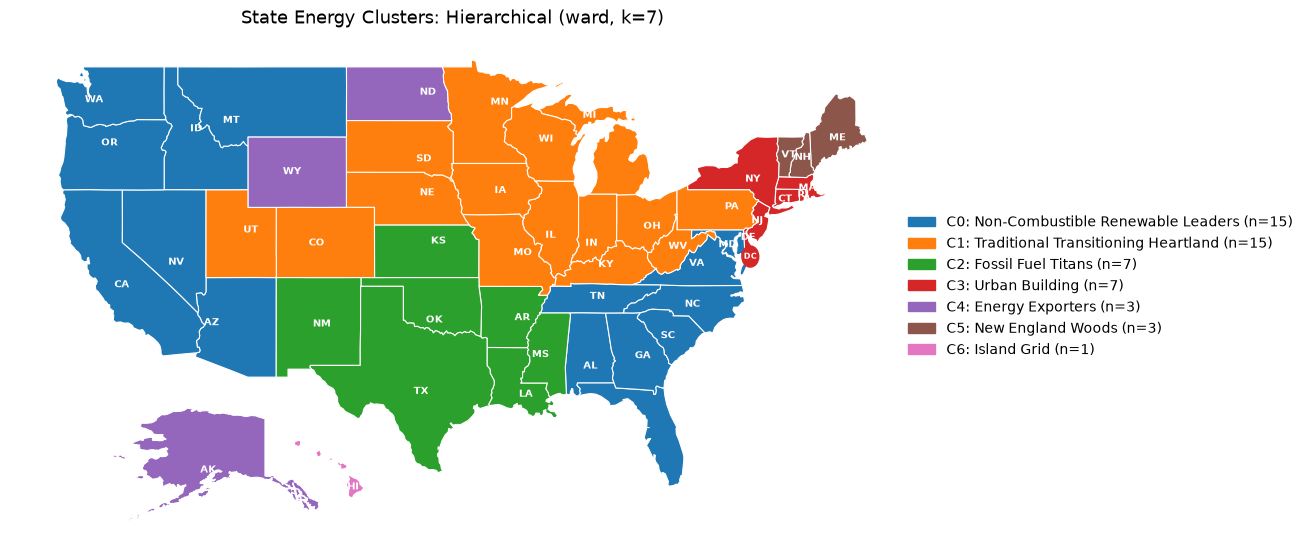

In [30]:
# Names written by hand from the profiles above mapped to their cluster IDs (0 to 6)
CLUSTER_NAMES = {
    0: "Non-Combustible Renewable Leaders",
    1: "Traditional Transitioning Heartland",
    2: "Fossil Fuel Titans",
    3: "Urban Building",
    4: "Energy Exporters",
    5: "New England Woods",
    6: "Island Grid"
}
cluster_label = {c: CLUSTER_NAMES.get(c, f"Cluster {c}") for c in range(FINAL_K)}
membership["cluster_name"] = membership["cluster_id"].map(cluster_label)
draw_map(final_labels, f"State Energy Clusters: {FINAL_MODEL}",
         "seds_state_cluster_map.png", cluster_names=CLUSTER_NAMES or None)

## Step 5.3: Export

`df_seds_state_clusters.csv`: the original data, unchanged, plus a `cluster_id` column. Each state has one cluster, so the same `cluster_id` appears on all of that state's rows.

In [31]:
out = df_raw.copy()
out["cluster_id"] = out["State"].map(cluster_of_state)
assert out["cluster_id"].notna().all() and len(out) == len(df_raw)
assert (out.groupby("State")["cluster_id"].nunique() == 1).all()
out.to_csv(Path(OUTPUT_DIR) / SEDS_CLUSTERS_CSV, index=False)
print(out.shape, "-> df_seds_state_clusters.csv")

(3315, 57) -> df_seds_state_clusters.csv
